# 多患者EEG Agent：疑似区间与局部证据复核

**实践B | 3名患者 | 6段×20分钟 | 本地Qwen3-8B | AMD R9700**

这是已保存结果回放，不重新加载大模型。公开标注用于选取每名患者的含发作/背景片段及事后评分，参考起止时间不进入Agent。这是在同一小样本上的功能预演，不能当作独立盲测或完整benchmark。

本页只展示修复schema字段别名问题后的fixed/final结果。早期main、guarded、refined目录保留为调试记录，不能用于评价模型或证明策略提升。不确定候选全部保留，并单独展示复核负担，避免把暂不判断当作误报消失。

|版本|完成|TP|FP|FN|不确定候选|复核队列TP/FP/FN|
|---|---|---|---|---|---|---|
|fixed|6/6|2|2|1|18|3/11/0|
|final|6/6|2|2|1|18|3/11/0|


## 数值检查及一次边界复核后的全部6例

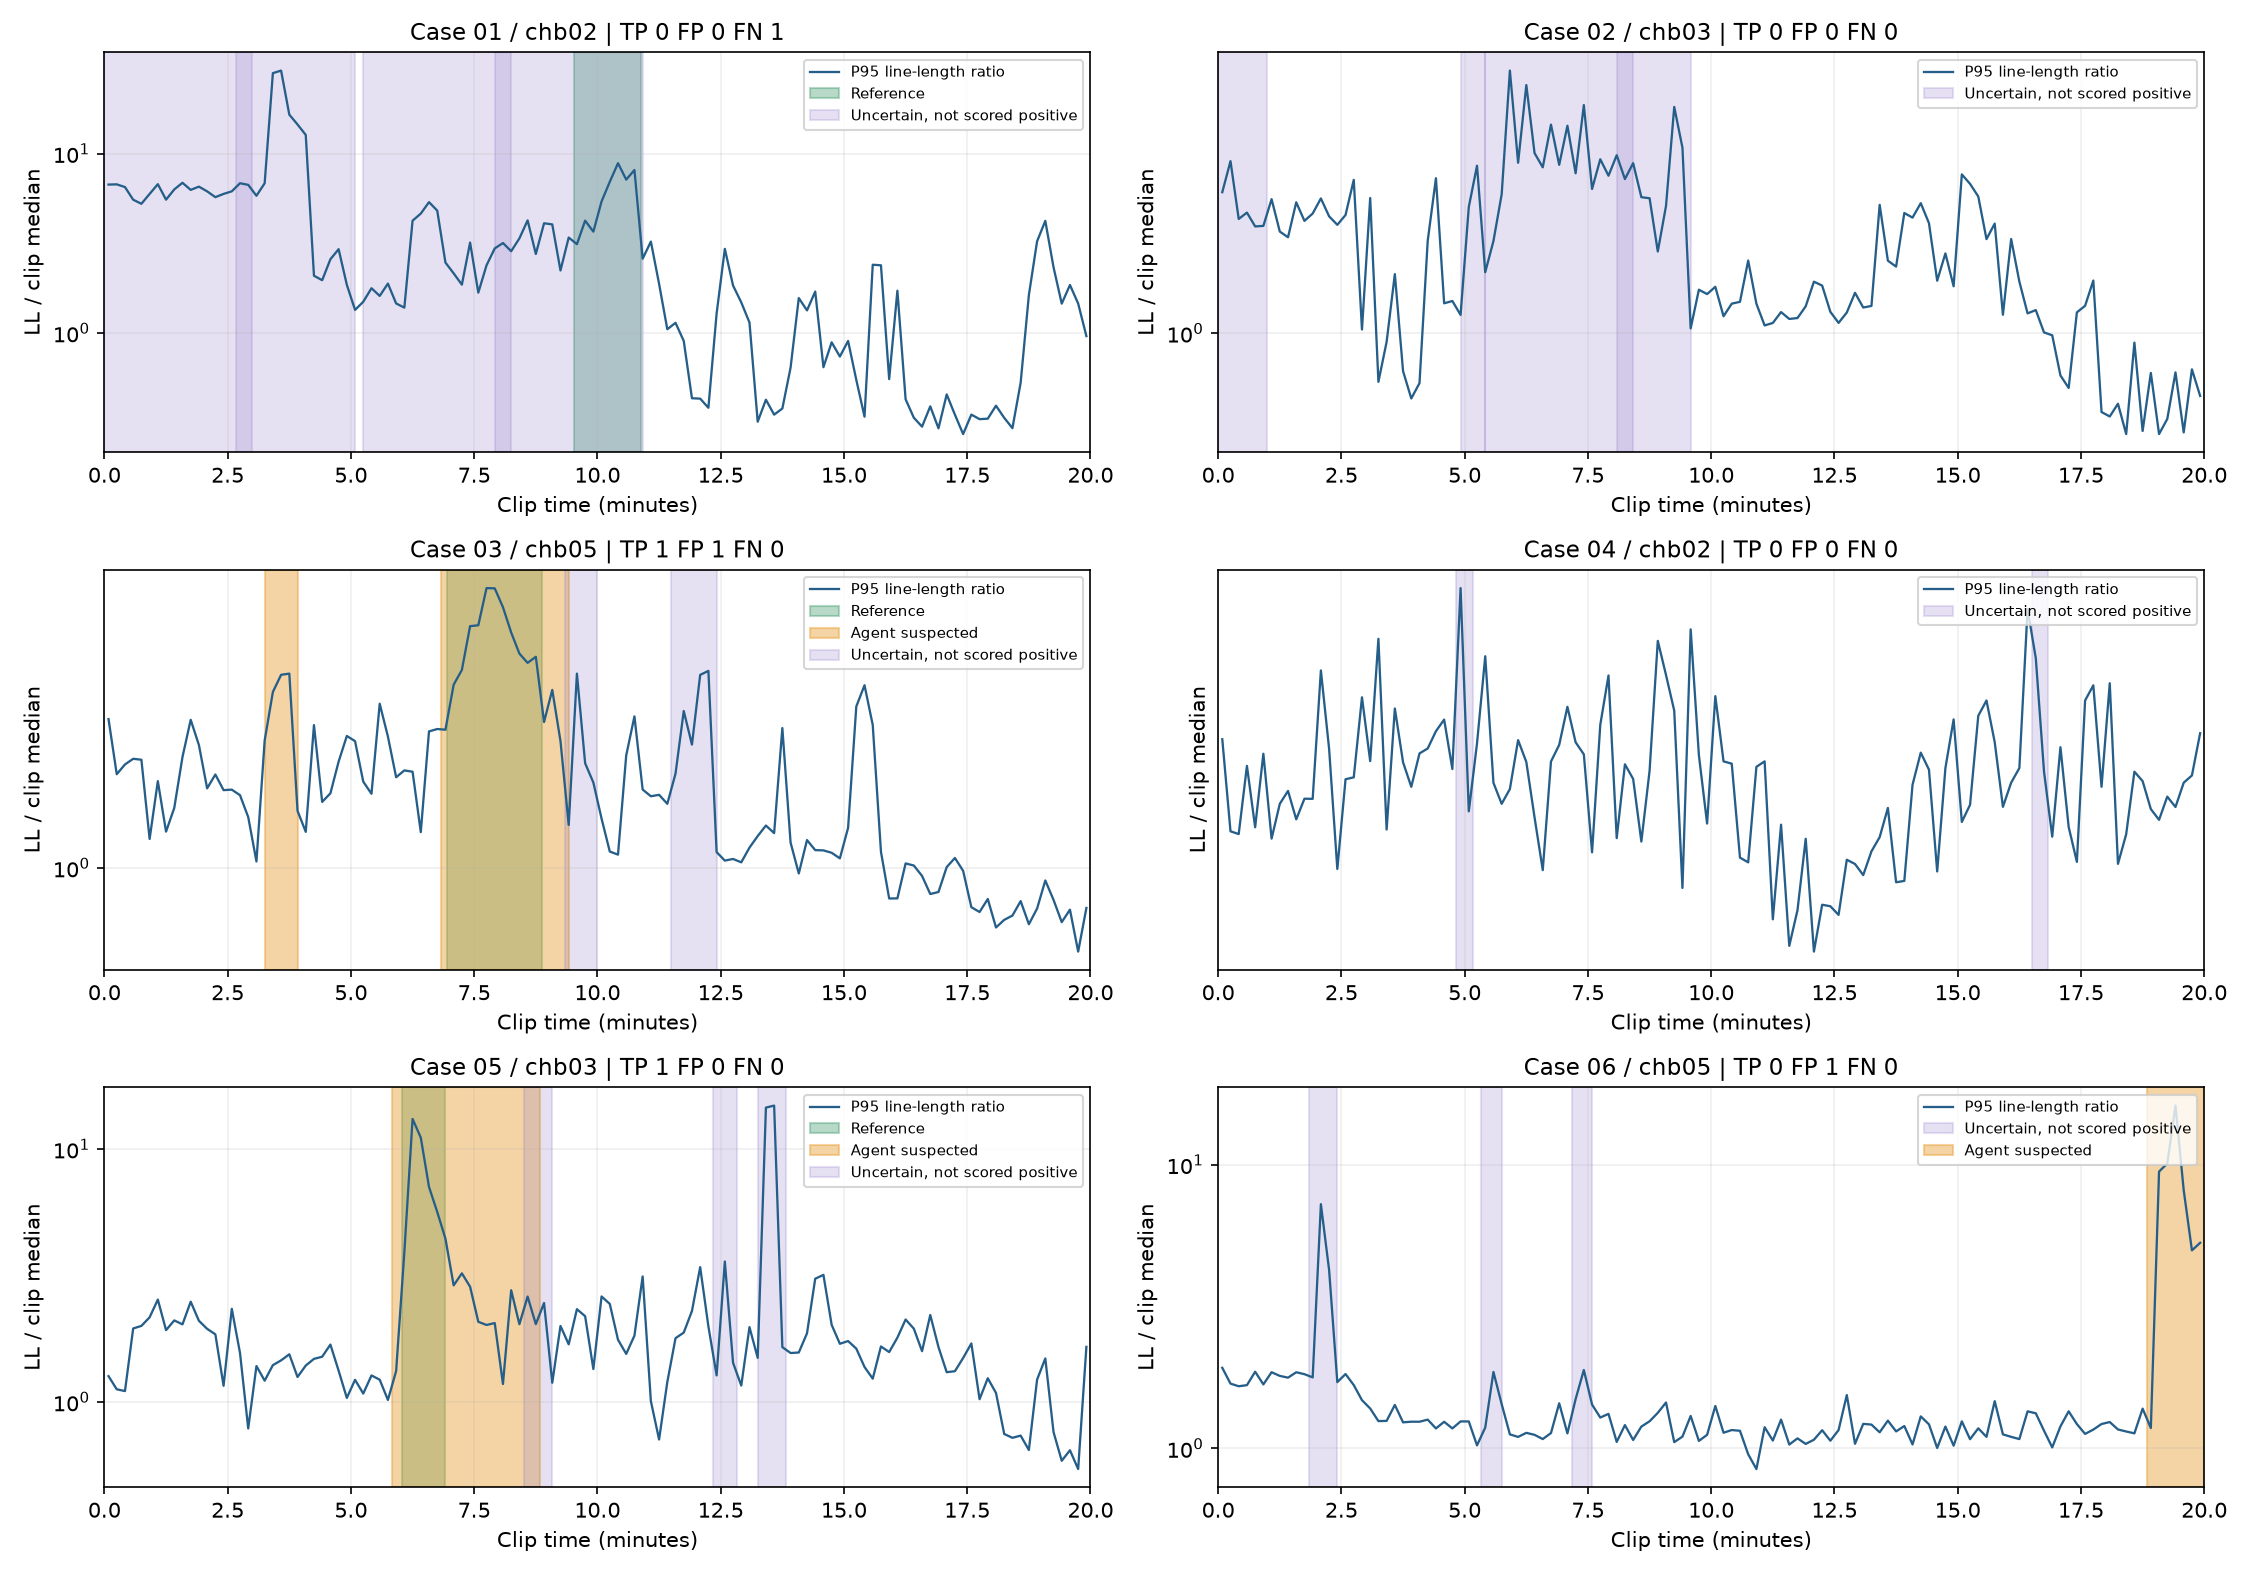

In [1]:
from pathlib import Path
import json
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
scores={name:json.loads((ROOT/f'results/{name}/score.json').read_text()) for name in ['fixed','final']}
table='|版本|完成|TP|FP|FN|不确定候选|复核队列TP/FP/FN|\n|---|---|---|---|---|---|---|\n'
for name,s in scores.items():
    q=s['inclusive_review_queue'];n=s['candidate_decisions']['uncertain']
    table+=f"|{name}|{s['completed']}/{s['n']}|{s['tp']}|{s['fp']}|{s['fn']}|{n}|{q['tp']}/{q['fp']}/{q['fn']}|\n"
display(Markdown(table))
display(Markdown('## 数值检查及一次边界复核后的全部6例'))
display(Image(filename=str(ROOT/'results/final/timeline_v2.png')))


## 查看每条候选的三类局部证据

可修改案例编号。每条候选都有时域、频谱、跨通道证据ID、测量范围和模型理由；完整数值及前/中/后对照表保存在证据卡。以下优先展示一条疑似候选，也可查看排除和不确定候选。

患者: chb05 参考: [[417.0, 532.0]]
全部候选: [('C1', 'suspected', 195.0, 235.0), ('C2', 'suspected', 410.0, 565.0), ('C3', 'uncertain', 560.0, 600.0), ('C4', 'uncertain', 690.0, 745.0)]


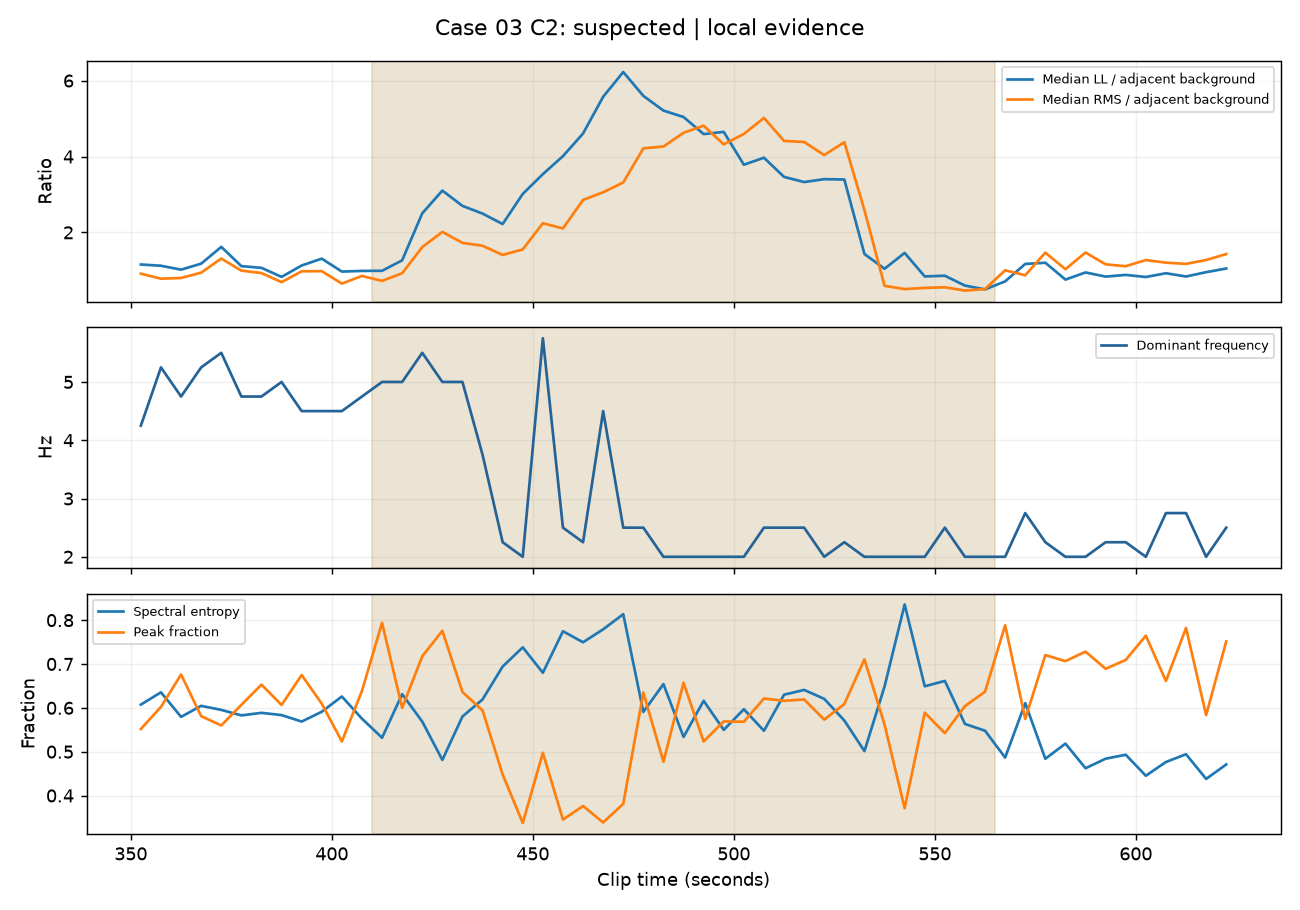

# 案例03 / 候选C2

决策：**suspected**；Agent区间：410.0–565.0秒；候选原区间：[410.0, 565.0]；实测复核区间：[350.0, 625.0]。

以下理由为模型解释，数值证据为真实工具计算；解释是否充分仍可复核。

|证据类别|编号|模型理由|
|---|---|---|
|时域|C2.temporal|The temporal evidence shows a significant increase in RMS and line length ratios across all channels during the interval [410.0, 565.0]. The ratios for P8-O2, F3-C3, C4-P4, and FZ-CZ increased from 0.9124 to 1.6117, 0.7799 to 1.3107, 0.7991 to 1.7249, and 0.9385 to 1.4061, respectively, indicating a sustained change in activity.|
|频谱|C2.spectral|The spectral evidence shows a marked shift in the dominant frequency and spectral entropy during the interval [410.0, 565.0]. The dominant frequency decreased from 4.75 to 2.0 Hz, and the spectral entropy increased from 0.6074 to 0.7747, indicating a change in the power distribution and complexity of the signal.|
|跨通道|C2.cross_channel|The cross-channel evidence shows a significant decrease in pairwise correlations during the interval [410.0, 565.0]. The correlations for P8-O2 and F3-C3 decreased from 0.1551 to -0.0522, indicating a loss of synchronization between channels, which is a potential sign of a focal seizure.|

替代解释：The changes observed could be due to a physiological state change or an artifact, but the sustained rhythmic evolution and spatial support suggest a potential seizure.


### 时域：数值顺序为前/中/后

| 导联 | RMS μV | 线长 μV/s | RMS比值 | 线长比值 |
| --- | --- | --- | --- | --- |
| P8-O2 | 48.725/107.233/46.973 | 1658.370/5816.643/1267.965 | 2.248 | 3.613 |
| F3-C3 | 81.798/224.463/110.751 | 1909.170/5690.517/1523.502 | 2.519 | 3.238 |
| C4-P4 | 36.730/114.952/58.622 | 1149.448/3633.099/1015.478 | 2.233 | 3.399 |
| FZ-CZ | 60.652/159.745/90.862 | 1526.645/4377.451/1233.698 | 2.247 | 3.254 |


### 频谱：数值顺序为前/中/后

| 导联 | 主频 Hz | 谱熵 | delta相对功率 | 谱峰集中度 |
| --- | --- | --- | --- | --- |
| P8-O2 | 4.750/2.500/2.000 | 0.636/0.713/0.629 | 0.290/0.509/0.637 | 0.577/0.477/0.541 |
| F3-C3 | 4.250/2.000/2.000 | 0.559/0.568/0.445 | 0.368/0.652/0.861 | 0.660/0.626/0.822 |
| C4-P4 | 5.000/2.000/2.000 | 0.620/0.639/0.496 | 0.292/0.567/0.761 | 0.564/0.538/0.664 |
| FZ-CZ | 5.000/2.500/2.000 | 0.567/0.578/0.461 | 0.307/0.700/0.829 | 0.664/0.609/0.775 |


### 跨通道：相关性含共享电极标记

| 导联对 | 之前 | 候选内 | 之后 | 共享电极 |
| --- | --- | --- | --- | --- |
| P8-O2 / F3-C3 | 0.155 | -0.052 | 0.091 | 否 |
| P8-O2 / C4-P4 | -0.175 | -0.164 | 0.185 | 否 |
| P8-O2 / FZ-CZ | 0.159 | -0.042 | 0.213 | 否 |
| F3-C3 / C4-P4 | 0.303 | 0.509 | 0.360 | 否 |
| F3-C3 / FZ-CZ | 0.771 | 0.869 | 0.725 | 否 |
| C4-P4 / FZ-CZ | 0.362 | 0.563 | 0.570 | 否 |

## 原始实测证据

```json
{
  "candidate_id": "C2",
  "proposed_interval": [
    410.0,
    565.0
  ],
  "review_interval": [
    350.0,
    625.0
  ],
  "channel_selection": "Top4 leads by candidate median LL ratio * sqrt(RMS ratio), using adjacent before/after windows as background; no annotation involved.",
  "channels": [
    "P8-O2",
    "F3-C3",
    "C4-P4",
    "FZ-CZ"
  ],
  "evidence_ids": {
    "temporal": "C2.temporal",
    "spectral": "C2.spectral",
    "cross_channel": "C2.cross_channel"
  },
  "temporal": {
    "local_ratios": {
      "P8-O2": {
        "rms_ratio": 2.2484,
        "line_length_ratio": 3.6126
      },
      "F3-C3": {
        "rms_ratio": 2.5187,
        "line_length_ratio": 3.2382
      },
      "C4-P4": {
        "rms_ratio": 2.2326,
        "line_length_ratio": 3.3993
      },
      "FZ-CZ": {
        "rms_ratio": 2.2473,
        "line_length_ratio": 3.2537
      }
    }
  },
  "spectral": {
    "before": {
      "P8-O2": {
        "rms_uv": 48.7247,
        "line_length_uv_s": 1658.3705,
        "delta_rel": 0.2902,
        "theta_rel": 0.5037,
        "alpha_rel": 0.0281,
        "beta_rel": 0.039,
        "gamma_rel": 0.0164,
        "dominant_hz": 4.75,
        "spectral_entropy": 0.6359,
        "peak_fraction": 0.5774,
        "kurtosis": 0.2771
      },
      "F3-C3": {
        "rms_uv": 81.7978,
        "line_length_uv_s": 1909.1705,
        "delta_rel": 0.3678,
        "theta_rel": 0.5033,
        "alpha_rel": 0.0159,
        "beta_rel": 0.0088,
        "gamma_rel": 0.0019,
        "dominant_hz": 4.25,
        "spectral_entropy": 0.5587,
        "peak_fraction": 0.6603,
        "kurtosis": -0.023
      },
      "C4-P4": {
        "rms_uv": 36.73,
        "line_length_uv_s": 1149.4483,
        "delta_rel": 0.2918,
        "theta_rel": 0.5699,
        "alpha_rel": 0.0366,
        "beta_rel": 0.0194,
        "gamma_rel": 0.0049,
        "dominant_hz": 5.0,
        "spectral_entropy": 0.6203,
        "peak_fraction": 0.5644,
        "kurtosis": 0.0625
      },
      "FZ-CZ": {
        "rms_uv": 60.6521,
        "line_length_uv_s": 1526.6452,
        "delta_rel": 0.3071,
        "theta_rel": 0.5954,
        "alpha_rel": 0.0169,
        "beta_rel": 0.0064,
        "gamma_rel": 0.001,
        "dominant_hz": 5.0,
        "spectral_entropy": 0.5672,
        "peak_fraction": 0.6639,
        "kurtosis": 0.0584
      }
    },
    "during": {
      "P8-O2": {
        "rms_uv": 107.2327,
        "line_length_uv_s": 5816.6431,
        "delta_rel": 0.5095,
        "theta_rel": 0.2142,
        "alpha_rel": 0.0559,
        "beta_rel": 0.084,
        "gamma_rel": 0.033,
        "dominant_hz": 2.5,
        "spectral_entropy": 0.7126,
        "peak_fraction": 0.4769,
        "kurtosis": 0.0858
      },
      "F3-C3": {
        "rms_uv": 224.4634,
        "line_length_uv_s": 5690.5172,
        "delta_rel": 0.652,
        "theta_rel": 0.1377,
        "alpha_rel": 0.0339,
        "beta_rel": 0.017,
        "gamma_rel": 0.0011,
        "dominant_hz": 2.0,
        "spectral_entropy": 0.5684,
        "peak_fraction": 0.626,
        "kurtosis": 0.2865
      },
      "C4-P4": {
        "rms_uv": 114.9523,
        "line_length_uv_s": 3633.0985,
        "delta_rel": 0.5674,
        "theta_rel": 0.2117,
        "alpha_rel": 0.0543,
        "beta_rel": 0.031,
        "gamma_rel": 0.0029,
        "dominant_hz": 2.0,
        "spectral_entropy": 0.6393,
        "peak_fraction": 0.5381,
        "kurtosis": 0.0369
      },
      "FZ-CZ": {
        "rms_uv": 159.7453,
        "line_length_uv_s": 4377.4508,
        "delta_rel": 0.7001,
        "theta_rel": 0.1605,
        "alpha_rel": 0.0356,
        "beta_rel": 0.0127,
        "gamma_rel": 0.0009,
        "dominant_hz": 2.5,
        "spectral_entropy": 0.5781,
        "peak_fraction": 0.6092,
        "kurtosis": 0.3755
      }
    },
    "after": {
      "P8-O2": {
        "rms_uv": 46.9734,
        "line_length_uv_s": 1267.9652,
        "delta_rel": 0.6367,
        "theta_rel": 0.1476,
        "alpha_rel": 0.0175,
        "beta_rel": 0.0378,
        "gamma_rel": 0.025,
        "dominant_hz": 2.0,
        "spectral_entropy": 0.629,
        "peak_fraction": 0.5407,
        "kurtosis": 0.7519
      },
      "F3-C3": {
        "rms_uv": 110.7507,
        "line_length_uv_s": 1523.5021,
        "delta_rel": 0.8614,
        "theta_rel": 0.0634,
        "alpha_rel": 0.0053,
        "beta_rel": 0.0016,
        "gamma_rel": 0.0005,
        "dominant_hz": 2.0,
        "spectral_entropy": 0.4452,
        "peak_fraction": 0.822,
        "kurtosis": 0.587
      },
      "C4-P4": {
        "rms_uv": 58.6216,
        "line_length_uv_s": 1015.4779,
        "delta_rel": 0.7611,
        "theta_rel": 0.1349,
        "alpha_rel": 0.0095,
        "beta_rel": 0.0052,
        "gamma_rel": 0.0012,
        "dominant_hz": 2.0,
        "spectral_entropy": 0.4963,
        "peak_fraction": 0.6644,
        "kurtosis": 0.4886
      },
      "FZ-CZ": {
        "rms_uv": 90.8616,
        "line_length_uv_s": 1233.6984,
        "delta_rel": 0.8286,
        "theta_rel": 0.0905,
        "alpha_rel": 0.0043,
        "beta_rel": 0.0017,
        "gamma_rel": 0.0003,
        "dominant_hz": 2.0,
        "spectral_entropy": 0.4611,
        "peak_fraction": 0.7755,
        "kurtosis": 0.299
      }
    }
  },
  "cross_channel": {
    "pairwise_correlations": [
      {
        "channels": [
          "P8-O2",
          "F3-C3"
        ],
        "before": 0.1551,
        "during": -0.0522,
        "after": 0.0907,
        "shared_electrode": false
      },
      {
        "channels": [
          "P8-O2",
          "C4-P4"
        ],
        "before": -0.1752,
        "during": -0.1637,
        "after": 0.1854,
        "shared_electrode": false
      },
      {
        "channels": [
          "P8-O2",
          "FZ-CZ"
        ],
        "before": 0.1591,
        "during": -0.0418,
        "after": 0.2132,
        "shared_electrode": false
      },
      {
        "channels": [
          "F3-C3",
          "C4-P4"
        ],
        "before": 0.3032,
        "during": 0.509,
        "after": 0.3603,
        "shared_electrode": false
      },
      {
        "channels": [
          "F3-C3",
          "FZ-CZ"
        ],
        "before": 0.7709,
        "during": 0.8693,
        "after": 0.7246,
        "shared_electrode": false
      },
      {
        "channels": [
          "C4-P4",
          "FZ-CZ"
        ],
        "before": 0.3622,
        "during": 0.5629,
        "after": 0.5703,
        "shared_electrode": false
      }
    ],
    "caution": "Shared electrodes can create correlation. Correlation alone is not seizure evidence; focal seizures need not be globally synchronous."
  },
  "time_series_columns": [
    "start",
    "end",
    "LL_ratio_p50",
    "RMS_ratio_p50",
    "dominant_hz_p50",
    "entropy_p50",
    "peak_fraction_p50",
    "changed_selected_leads"
  ],
  "time_series": [
    [
      350.0,
      355.0,
      1.1543,
      0.9124,
      4.25,
      0.6074,
      0.5518,
      0
    ],
    [
      355.0,
      360.0,
      1.1214,
      0.7799,
      5.25,
      0.6354,
      0.6022,
      0
    ],
    [
      360.0,
      365.0,
      1.0181,
      0.7991,
      4.75,
      0.5794,
      0.676,
      0
    ],
    [
      365.0,
      370.0,
      1.1763,
      0.9385,
      5.25,
      0.6046,
      0.5811,
      0
    ],
    [
      370.0,
      375.0,
      1.6185,
      1.3107,
      5.5,
      0.5953,
      0.5598,
      0
    ],
    [
      375.0,
      380.0,
      1.1113,
      0.9928,
      4.75,
      0.5828,
      0.6068,
      0
    ],
    [
      380.0,
      385.0,
      1.0656,
      0.9286,
      4.75,
      0.5886,
      0.653,
      0
    ],
    [
      385.0,
      390.0,
      0.8275,
      0.6887,
      5.0,
      0.5835,
      0.6066,
      0
    ],
    [
      390.0,
      395.0,
      1.1275,
      0.9751,
      4.5,
      0.5687,
      0.6749,
      0
    ],
    [
      395.0,
      400.0,
      1.3082,
      0.9788,
      4.5,
      0.5911,
      0.6095,
      1
    ],
    [
      400.0,
      405.0,
      0.9674,
      0.6507,
      4.5,
      0.6259,
      0.5233,
      0
    ],
    [
      405.0,
      410.0,
      0.985,
      0.8527,
      4.75,
      0.5753,
      0.6387,
      0
    ],
    [
      410.0,
      415.0,
      0.9885,
      0.7224,
      5.0,
      0.5318,
      0.794,
      0
    ],
    [
      415.0,
      420.0,
      1.2641,
      0.9226,
      5.0,
      0.6312,
      0.5999,
      0
    ],
    [
      420.0,
      425.0,
      2.5024,
      1.6117,
      5.5,
      0.5687,
      0.7176,
      2
    ],
    [
      425.0,
      430.0,
      3.1022,
      2.0131,
      5.0,
      0.4812,
      0.7756,
      3
    ],
    [
      430.0,
      435.0,
      2.6987,
      1.7249,
      5.0,
      0.5802,
      0.6362,
      4
    ],
    [
      435.0,
      440.0,
      2.4954,
      1.6476,
      3.75,
      0.6192,
      0.5941,
      3
    ],
    [
      440.0,
      445.0,
      2.2205,
      1.4061,
      2.25,
      0.6942,
      0.4479,
      1
    ],
    [
      445.0,
      450.0,
      3.0144,
      1.5519,
      2.0,
      0.738,
      0.3373,
      2
    ],
    [
      450.0,
      455.0,
      3.5344,
      2.2405,
      5.75,
      0.68,
      0.4974,
      4
    ],
    [
      455.0,
      460.0,
      4.0097,
      2.105,
      2.5,
      0.7747,
      0.3451,
      4
    ],
    [
      460.0,
      465.0,
      4.6054,
      2.8549,
      2.25,
      0.7496,
      0.3761,
      4
    ],
    [
      465.0,
      470.0,
      5.5739,
      3.057,
      4.5,
      0.7791,
      0.3386,
      4
    ],
    [
      470.0,
      475.0,
      6.226,
      3.316,
      2.5,
      0.8136,
      0.381,
      4
    ],
    [
      475.0,
      480.0,
      5.5978,
      4.2147,
      2.5,
      0.5907,
      0.6348,
      4
    ],
    [
      480.0,
      485.0,
      5.21,
      4.2633,
      2.0,
      0.6542,
      0.4771,
      4
    ],
    [
      485.0,
      490.0,
      5.0406,
      4.6248,
      2.0,
      0.5337,
      0.6571,
      4
    ],
    [
      490.0,
      495.0,
      4.5908,
      4.8114,
      2.0,
      0.6161,
      0.5233,
      4
    ],
    [
      495.0,
      500.0,
      4.6487,
      4.3186,
      2.0,
      0.5497,
      0.569,
      4
    ],
    [
      500.0,
      505.0,
      3.7837,
      4.5942,
      2.0,
      0.5969,
      0.5683,
      4
    ],
    [
      505.0,
      510.0,
      3.9682,
      5.0164,
      2.5,
      0.5477,
      0.6213,
      4
    ],
    [
      510.0,
      515.0,
      3.463,
      4.411,
      2.5,
      0.63,
      0.616,
      4
    ],
    [
      515.0,
      520.0,
      3.3265,
      4.3828,
      2.5,
      0.6409,
      0.6191,
      4
    ],
    [
      520.0,
      525.0,
      3.4031,
      4.0383,
      2.0,
      0.6205,
      0.5732,
      4
    ],
    [
      525.0,
      530.0,
      3.3935,
      4.3775,
      2.25,
      0.571,
      0.6088,
      4
    ],
    [
      530.0,
      535.0,
      1.4307,
      2.5858,
      2.0,
      0.5013,
      0.7107,
      1
    ],
    [
      535.0,
      540.0,
      1.0421,
      0.5924,
      2.0,
      0.6486,
      0.5619,
      0
    ],
    [
      540.0,
      545.0,
      1.4592,
      0.5059,
      2.0,
      0.8358,
      0.371,
      0
    ],
    [
      545.0,
      550.0,
      0.8398,
      0.5381,
      2.0,
      0.6492,
      0.589,
      0
    ],
    [
      550.0,
      555.0,
      0.8582,
      0.5532,
      2.5,
      0.6614,
      0.5423,
      0
    ],
    [
      555.0,
      560.0,
      0.5985,
      0.4669,
      2.0,
      0.5633,
      0.604,
      0
    ],
    [
      560.0,
      565.0,
      0.4978,
      0.5074,
      2.0,
      0.5478,
      0.6368,
      0
    ],
    [
      565.0,
      570.0,
      0.7095,
      1.0016,
      2.0,
      0.4866,
      0.7883,
      0
    ],
    [
      570.0,
      575.0,
      1.1691,
      0.8696,
      2.75,
      0.6108,
      0.5747,
      0
    ],
    [
      575.0,
      580.0,
      1.2002,
      1.4662,
      2.25,
      0.4839,
      0.7203,
      1
    ],
    [
      580.0,
      585.0,
      0.7567,
      1.0298,
      2.0,
      0.5184,
      0.7065,
      0
    ],
    [
      585.0,
      590.0,
      0.9444,
      1.4692,
      2.0,
      0.4623,
      0.7282,
      0
    ],
    [
      590.0,
      595.0,
      0.835,
      1.1581,
      2.25,
      0.484,
      0.6891,
      0
    ],
    [
      595.0,
      600.0,
      0.8797,
      1.1084,
      2.25,
      0.493,
      0.7093,
      0
    ],
    [
      600.0,
      605.0,
      0.8245,
      1.2714,
      2.0,
      0.4451,
      0.7647,
      0
    ],
    [
      605.0,
      610.0,
      0.9239,
      1.2024,
      2.75,
      0.4765,
      0.6612,
      0
    ],
    [
      610.0,
      615.0,
      0.8378,
      1.1708,
      2.75,
      0.4942,
      0.7822,
      0
    ],
    [
      615.0,
      620.0,
      0.9518,
      1.272,
      2.0,
      0.4379,
      0.5836,
      0
    ],
    [
      620.0,
      625.0,
      1.0487,
      1.4297,
      2.5,
      0.4708,
      0.7514,
      0
    ]
  ],
  "caution": "High delta power alone is nonspecific. Compare candidate with before/after, sustained evolution, rhythmicity, and artifact alternatives. A high change score is not a diagnosis."
}
```

In [2]:
case_id=3  # 1至6；默认展示一次命中的局部证据
candidate_id='C2'  # 可改为该案例内的其他候选；不存在时显示第一条
case=next(c for c in scores['final']['cases'] if c['case']==case_id)
ds=case['prediction']['candidates']
print('患者:',case['subject'],'参考:',case['reference_events'])
print('全部候选:',[(d['candidate_id'],d['decision'],d['onset_sec'],d['offset_sec']) for d in ds])
if ds:
    d=next((d for d in ds if d['candidate_id']==candidate_id),ds[0])
    folder=ROOT/f'results/final/case_{case_id:02d}'
    display(Image(filename=str(folder/(d['candidate_id']+'_local.png'))))
    display(Markdown((folder/(d['candidate_id']+'_证据卡.md')).read_text()))
else:
    print('本例未提出候选，完整扫描仍保存在scan.json。')


## 工具调用与下一步

接口按阶段提供合法工具，限制整段重复分析；测量缓存与证据ID检查已有预检。编号对应与数值门槛只解决一部分可靠性问题，不能证明模型给出的医学解释正确。仍需增加患者、伪迹类型、低幅度事件，并用独立固定数据检查误报与漏检的平衡。

完整轨迹见`results/fixed`及`results/final`，复现命令见README。人工核对发现的数值混用、相关性误读与边缘背景缺失见`证据审阅与改进规划.md`；模型文字尚未通过逐项事实认证。本页记录公开仓库所附的云端预演结果。

In [3]:
print(json.dumps(scores['final']['tool_statistics'],ensure_ascii=False,indent=2))


{
  "model_calls": 68,
  "tool_dispatches": 34,
  "measurements_executed": 28,
  "cache_hits": 0,
  "invalid_calls": 0,
  "submission_rejections": 0
}
